# analyze proportion search

How much of the metagenome is made up by these 16 species?

In [1]:
import polars as pl
import matplotlib.pyplot as plt

In [2]:
df = pl.read_csv('../outputs.proportion/combined-pangenomes.x.3216.csv').with_columns(
    f_weighted=pl.col('n_weighted_found') / pl.col('total_weighted_hashes'),
    acc=pl.col('match_name'),
)
df

query_name,query_md5,match_name,containment,intersect_hashes,ksize,scaled,moltype,match_md5,jaccard,max_containment,average_abund,median_abund,std_abund,query_containment_ani,match_containment_ani,average_containment_ani,max_containment_ani,n_weighted_found,total_weighted_hashes,f_weighted,acc
str,str,str,f64,i64,i64,i64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,f64,str
"""entire""","""98dbe5697ef24915ca702ff3ba323e…","""SRR11125972""",0.121349,20713,21,1000,"""DNA""","""a677ed5a89bacd7755d1f8d0c8d2c0…",0.037216,0.121349,8.287935,2.0,20.125202,0.904446,0.867826,0.886136,0.904446,171668,1025328,0.167427,"""SRR11125972"""
"""specific""","""7cc408671d6c69e40ff2ba0829df1b…","""SRR11125972""",0.084264,5959,21,1000,"""DNA""","""a677ed5a89bacd7755d1f8d0c8d2c0…",0.012642,0.084264,5.588018,2.0,11.110995,0.888874,0.817838,0.853356,0.888874,33299,1025328,0.032476,"""SRR11125972"""
"""GCA_945877245 s__Bariatricus s…","""1e6e40f2bac884f45d671f9d03d817…","""SRR11125972""",0.166514,1089,21,1000,"""DNA""","""a677ed5a89bacd7755d1f8d0c8d2c0…",0.002643,0.166514,6.261708,2.0,24.506711,0.918177,0.754254,0.836215,0.918177,6819,1025328,0.006651,"""SRR11125972"""
"""GCA_947072165 s__Colivicinus s…","""2fd38015561463f21785852e62344d…","""SRR11125972""",0.030828,162,21,1000,"""DNA""","""a677ed5a89bacd7755d1f8d0c8d2c0…",0.000394,0.030828,7.666667,2.0,25.986939,0.847315,0.68883,0.768073,0.847315,1242,1025328,0.001211,"""SRR11125972"""
"""GCA_902796665 s__Cryptobactero…","""4a8aa84a039c9eab7eb8c131b0fdac…","""SRR11125972""",0.048985,550,21,1000,"""DNA""","""a677ed5a89bacd7755d1f8d0c8d2c0…",0.001318,0.048985,5.863636,2.0,38.056149,0.866207,0.730114,0.798161,0.866207,3225,1025328,0.003145,"""SRR11125972"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""GCA_022772045 s__Sodaliphilus …","""fde1a942736a2aee581fd2362d4a1c…","""SRR17241535""",0.245046,2943,21,1000,"""DNA""","""04dae700326a1da375318423ed3722…",0.000928,0.245046,17.288821,10.0,17.296799,0.935226,0.717239,0.826232,0.935226,50881,22812667,0.00223,"""SRR17241535"""
"""GCA_902468955 s__Cryptobactero…","""407ba08f4c7f4c1cd05b67c9e974d5…","""SRR17241535""",0.23124,4727,21,1000,"""DNA""","""04dae700326a1da375318423ed3722…",0.001488,0.23124,33.006135,14.0,282.50997,0.932647,0.733607,0.833127,0.932647,156020,22812667,0.006839,"""SRR17241535"""
"""GCA_028721505 s__Cryptobactero…","""f3d894b7f127d02f0e36f11f946068…","""SRR17241535""",0.377386,1048,21,1000,"""DNA""","""04dae700326a1da375318423ed3722…",0.000331,0.377386,5.744275,4.0,12.382172,0.954656,0.682826,0.818741,0.954656,6020,22812667,0.000264,"""SRR17241535"""


In [3]:
singlehash_df = df.filter(pl.col('query_name') == 'specific').with_columns(
    specific_f_weighted=pl.col('f_weighted')
).select(['acc', 'specific_f_weighted'])
singlehash_df

acc,specific_f_weighted
str,f64
"""SRR11125972""",0.032476
"""SRR11124793""",0.052649
"""SRR11126271""",0.043871
"""SRR11183449""",0.034219
"""SRR11125483""",0.023856
…,…
"""SRR8960867""",0.031299
"""SRR17241515""",0.001241
"""SRR14812376""",0.026263


In [4]:
full_pang_df = df.filter(pl.col('query_name') == 'entire').with_columns(
        entire_f_weighted=pl.col('f_weighted')
).select(['acc', 'entire_f_weighted'])
full_pang_df

acc,entire_f_weighted
str,f64
"""SRR11125972""",0.167427
"""SRR11124793""",0.304294
"""SRR11126271""",0.254987
"""SRR11183449""",0.163088
"""SRR11125483""",0.121289
…,…
"""SRR8960867""",0.144074
"""SRR17241515""",0.042928
"""SRR14812376""",0.10566


In [6]:
#assert len(singlehash_df) + len(full_pang_df) == len(df)

In [7]:
combo_df = full_pang_df.join(singlehash_df, on=['acc'], how='left').fill_null(0)

In [8]:
combo_df

acc,entire_f_weighted,specific_f_weighted
str,f64,f64
"""SRR11125972""",0.167427,0.032476
"""SRR11124793""",0.304294,0.052649
"""SRR11126271""",0.254987,0.043871
"""SRR11183449""",0.163088,0.034219
"""SRR11125483""",0.121289,0.023856
…,…,…
"""SRR8960867""",0.144074,0.031299
"""SRR17241515""",0.042928,0.001241
"""SRR14812376""",0.10566,0.026263


In [19]:
species_df = df.filter(
    ~(pl.col('query_name').is_in(['entire', 'specific'])) &
    ~(pl.col('query_name').str.contains('singlehash'))
).with_columns(
    species=pl.col('query_name').str.split(' ').list.slice(1,3).list.join(" ")
).select(
    ['acc', 'species', 'f_weighted']
)
species_pdf = species_df.pivot("species", index="acc", values="f_weighted", aggregate_function="first")

In [21]:
by_metag = (combo_df
    .group_by('acc').agg(
        sum_entire=pl.col('entire_f_weighted').sum(),
        sum_specific=pl.col('specific_f_weighted').sum(),
    )
    .join(species_pdf, on='acc')        
    .sort('sum_entire', descending=True).with_row_index('sum_index')
           )
by_metag

sum_index,acc,sum_entire,sum_specific,s__Bariatricus sp004560705,s__Colivicinus sp002299675,s__Cryptobacteroides sp000432655,s__Cryptobacteroides sp000434935,s__Cryptobacteroides sp034089285,s__Cryptobacteroides sp900546925,s__Fimisoma sp002320005,s__Floccifex porci,s__JAFBIX01 sp021531895,s__Lactobacillus amylovorus,s__Mogibacterium_A kristiansenii,s__Ornithospirochaeta sp022785155,s__Prevotella sp000434975,s__Prevotella sp002251295,s__Sodaliphilus sp004557565,s__UBA2868 sp004552595
u32,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,"""SRR16235687""",0.573898,0.086898,0.002898,0.001717,0.000977,0.002197,0.000243,0.004028,0.001274,0.003011,0.002819,0.557114,0.000899,0.000027,0.009048,0.001486,0.005005,0.000895
1,"""SRR16235689""",0.519878,0.080084,0.006006,0.003221,0.001964,0.003408,0.000962,0.005634,0.002129,0.003046,0.00546,0.478886,0.001598,0.000056,0.010241,0.007381,0.018797,0.001528
2,"""SRR16235702""",0.472943,0.068907,0.0047,0.003111,0.002245,0.00387,0.000667,0.00598,0.001862,0.002268,0.005244,0.432817,0.001287,0.000074,0.013442,0.009685,0.01494,0.00166
3,"""SRR11124831""",0.45468,0.081287,0.002985,0.002447,0.002377,0.00313,0.00104,0.005567,0.002697,0.00485,0.004037,0.394816,0.030159,0.000313,0.001824,0.001451,0.004581,0.016244
4,"""SRR11126113""",0.453916,0.080566,0.00305,0.0026,0.002379,0.003211,0.000908,0.005618,0.002586,0.004948,0.004122,0.394761,0.029415,0.000334,0.00192,0.001477,0.004583,0.016465
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
3211,"""SRR11489765""",0.007408,0.000081,0.000505,0.000744,0.000295,0.000479,0.000224,0.002506,0.000391,0.000246,0.000647,0.001628,0.000528,0.000007,0.000999,0.000276,0.000879,0.000186
3212,"""SRR8655118""",0.007008,0.000468,0.000702,0.000092,0.00112,0.001233,0.00044,0.001578,0.00039,0.000384,0.000893,0.002226,0.000689,0.000072,0.002044,0.00103,0.001856,0.00039
3213,"""SRR8655120""",0.006933,0.000323,0.000683,0.000075,0.001241,0.001423,0.000526,0.001763,0.00037,0.000382,0.00087,0.001921,0.000747,0.000056,0.002375,0.001394,0.002205,0.000282


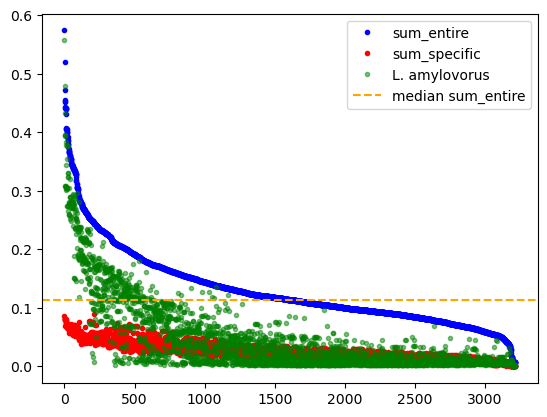

In [23]:
plt.plot(by_metag['sum_index'], by_metag['sum_entire'], 'b.', label='sum_entire')
plt.plot(by_metag['sum_index'], by_metag['sum_specific'], 'r.', label='sum_specific')
plt.plot(by_metag['sum_index'], by_metag['s__Lactobacillus amylovorus'], 'g.', label='L. amylovorus', alpha=0.5)
plt.axhline(by_metag['sum_entire'].median(), color='orange', linestyle='--', label='median sum_entire')
plt.legend(loc='upper right')

In [11]:
by_metag.describe()

statistic,sum_index,acc,sum_entire,sum_specific
str,f64,str,f64,f64
"""count""",3216.0,"""3216""",3216.0,3216.0
"""null_count""",0.0,"""0""",0.0,0.0
"""mean""",1607.5,null,0.1312,0.026304
"""std""",928.523559,null,0.067754,0.014617
"""min""",0.0,"""ERR1135178""",0.005774,0.000008
"""25%""",804.0,null,0.088132,0.01612
"""50%""",1608.0,null,0.114008,0.022988
"""75%""",2411.0,null,0.159525,0.034219
"""max""",3215.0,"""SRR8960986""",0.573898,0.088915
